# Setup

In [ ]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import pandas as pd
import numpy as np

# Train-test Split & Normalization
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Learners
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Class Imbalance Handling
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import SimpleImputer
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    make_scorer,
    roc_curve,
    roc_auc_score
)
import matplotlib.pyplot as plt

# 1. Data Loading & Missing-value Check

In [ ]:
df = pd.read_csv("Bankruptcy.csv")

print(f" Dataset Shape : {df.shape}")
print(f"\nColumns:\n{df.columns.tolist()}")
print("\nClass distribution:")
print(df["Bankrupt?"].value_counts())

 Dataset Shape : (6819, 96)

Columns:
['Bankrupt?', ' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)', ' Operating Expense Rate', ' Research and development expense rate', ' Cash flow rate', ' Interest-bearing debt interest rate', ' Tax rate (A)', ' Net Value Per Share (B)', ' Net Value Per Share (A)', ' Net Value Per Share (C)', ' Persistent EPS in the Last Four Seasons', ' Cash Flow Per Share', ' Revenue Per Share (Yuan ¥)', ' Operating Profit Per Share (Yuan ¥)', ' Per Share Net profit before tax (Yuan ¥)', ' Realized Sales Gross Profit Growth Rate', ' Operating Profit Growth Rate', ' After-tax Net Profit Growth Rate', ' Regular Net Profit Growth 

In [ ]:
print("Missing values:", df.isnull().sum().sum())
df.isnull().sum().sort_values(ascending=True)

Missing values: 0


,0
Bankrupt?,0
ROA(C) before interest and depreciation before interest,0
ROA(A) before interest and % after tax,0
ROA(B) before interest and depreciation after tax,0
Operating Gross Margin,0
...,...
Liability to Equity,0
Degree of Financial Leverage (DFL),0
Interest Coverage Ratio (Interest expense to EBIT),0
Net Income Flag,0


## 2. Preprocessing Pipeline

In [ ]:
X = df.drop(columns=["Bankrupt?"])
y = df["Bankrupt?"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print(f"Training shape: {X_train.shape[0]} rows, {X_train.shape[1]} columns")
print(f"Testing shape: {X_test.shape[0]} rows, {X_train.shape[1]} columns")

# Same class proportion in training & test sets
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

Training shape: 5455 rows, 95 columns
Testing shape: 1364 rows, 95 columns

Training class distribution:
Bankrupt?
0    0.967736
1    0.032264
Name: proportion, dtype: float64

Testing class distribution:
Bankrupt?
0    0.967742
1    0.032258
Name: proportion, dtype: float64


# 3. Baseline Model Development

In [ ]:
# 1. Majority Classifier
majority = DummyClassifier(strategy="most_frequent")

# 2. Logistic Regression
logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

# 3. Shallow Decision Tree
dt_bl = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)


# Define baseline models
baseline_models = {
    "Majority Classifier": majority,
    "Logistic Regression": logistic,
    "Shallow Decision Tree": dt_bl
}

# Define 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-score": "f1",
    "Average Precision": "average_precision"
}

# Store evaluation results
baseline_results = []

for name, model in baseline_models.items():

    # Evaluate using cross-validation on training data
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    # Calculate mean and standard deviation across folds
    baseline_results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1-score": scores["test_F1-score"].mean(),
        "Average Precision": scores["test_Average Precision"].mean(),
        "AP Std": scores["test_Average Precision"].std()
    })

# Convert results into a DataFrame
baseline_results_df = pd.DataFrame(baseline_results)

display(baseline_results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,Majority Classifier,0.9677,0.0000,0.0000,0.0000,0.0323,0.0004
1,Logistic Regression,0.9674,0.4849,0.2160,0.2973,0.3560,0.0300
2,Shallow Decision Tree,0.9644,0.4229,0.2387,0.3015,0.2810,0.0683


# 4. Model Development

## 4.1. Hyperparameter Tuning

Logistic Regression with Hyperparameter Tuning

In [ ]:
# Logistic Regression pipeline
logistic_tuning = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=42
    ))
])

# Hyperparameter grid
logistic_param_grid = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Grid Search using 5-Fold Stratified CV
logistic_grid = GridSearchCV(
    estimator=logistic_tuning,
    param_grid=logistic_param_grid,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1-score": "f1",
        "Average Precision": "average_precision"
    },
    refit="Average Precision",
    cv=cv,
    n_jobs=-1
)

# Model fit
logistic_grid.fit(X_train, y_train)

# Best hyperparameter combination
print("Best Parameters:")
print(logistic_grid.best_params_)

# Index of the best hyperparameter combination
logistic_best_index = logistic_grid.best_index_

# Store tuned Logistic Regression results
logistic_tuned_results = [{
    "Model": "Tuned Logistic Regression",

    "Accuracy": logistic_grid.cv_results_[
        "mean_test_Accuracy"
    ][logistic_best_index],

    "Precision": logistic_grid.cv_results_[
        "mean_test_Precision"
    ][logistic_best_index],

    "Recall": logistic_grid.cv_results_[
        "mean_test_Recall"
    ][logistic_best_index],

    "F1-score": logistic_grid.cv_results_[
        "mean_test_F1-score"
    ][logistic_best_index],

    "Average Precision": logistic_grid.cv_results_[
        "mean_test_Average Precision"
    ][logistic_best_index],

    "AP Std": logistic_grid.cv_results_[
        "std_test_Average Precision"
    ][logistic_best_index]
}]


logistic_tuned_results_df = pd.DataFrame(logistic_tuned_results)
display(logistic_tuned_results_df.round(4))

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        LogisticRegression(max_iter=5000,
                                                           random_state=42,
                                                           solver='saga'))]),
             n_jobs=-1,
             param_grid={'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'model__penalty': ['l1', 'l2']},
             refit='Average Precision',
             scoring={'Accuracy': 'accuracy',
                      'Average Precision': 'average_precision',
                      'F1-score': 'f1', 'Precision': 'precision',
                      'Recall': 'recall'})

Best Parameters:
{'model__C': 0.1, 'model__penalty': 'l1'}


,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,Tuned Logistic Regression,0.9687,0.5481,0.1533,0.2386,0.377,0.0316


Decision Tree with Hyperparameter Tuning

In [ ]:
# Decision Tree for hyperparameter tuning
dt_tuning = DecisionTreeClassifier(
    random_state=42
)

# Hyperparameters to test
dt_param_grid = {
    "max_depth": [3, 5, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 5, 10, 20]
}

# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
dt_search = GridSearchCV(
    estimator=dt_tuning,
    param_grid=dt_param_grid,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1-score": "f1",
        "Average Precision": "average_precision"
    },
    refit="Average Precision",
    cv=cv,
    n_jobs=-1
)

# Model fit
dt_search.fit(X_train, y_train)

print("Best parameters:")
print(dt_search.best_params_)

# Index of the best hyperparameter combination
dt_best_index = dt_search.best_index_

# Store tuned Decision Tree results
dt_tuned_results = [{
    "Model": "Tuned Decision Tree",
    "Accuracy": dt_search.cv_results_[
        "mean_test_Accuracy"
    ][dt_best_index],
    "Precision": dt_search.cv_results_[
        "mean_test_Precision"
    ][dt_best_index],
    "Recall": dt_search.cv_results_[
        "mean_test_Recall"
    ][dt_best_index],
    "F1-score": dt_search.cv_results_[
        "mean_test_F1-score"
    ][dt_best_index],
    "Average Precision": dt_search.cv_results_[
        "mean_test_Average Precision"
    ][dt_best_index],
    "AP Std": dt_search.cv_results_[
        "std_test_Average Precision"
    ][dt_best_index]
}]

dt_tuned_results_df = pd.DataFrame(dt_tuned_results)
display(dt_tuned_results_df.round(4))

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 8, 10, None],
                         'min_samples_leaf': [1, 5, 10, 20],
                         'min_samples_split': [2, 5, 10, 20]},
             refit='Average Precision',
             scoring={'Accuracy': 'accuracy',
                      'Average Precision': 'average_precision',
                      'F1-score': 'f1', 'Precision': 'precision',
                      'Recall': 'recall'})

Best parameters:
{'max_depth': 5, 'min_samples_leaf': 20, 'min_samples_split': 2}


,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,Tuned Decision Tree,0.9641,0.4267,0.2667,0.3189,0.2853,0.0486


In [ ]:
all_models_results_df = pd.concat(
    [
        baseline_results_df,
        logistic_tuned_results_df,
        dt_tuned_results_df
    ],
    ignore_index=True
)

# Display comparison table
display(all_models_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,Majority Classifier,0.9677,0.0000,0.0000,0.0000,0.0323,0.0004
1,Logistic Regression,0.9674,0.4849,0.2160,0.2973,0.3560,0.0300
2,Shallow Decision Tree,0.9644,0.4229,0.2387,0.3015,0.2810,0.0683
3,Tuned Logistic Regression,0.9687,0.5481,0.1533,0.2386,0.3770,0.0316
4,Tuned Decision Tree,0.9641,0.4267,0.2667,0.3189,0.2853,0.0486


## 4.2. Class Imbalance Handling

In [ ]:
# Best Decision Tree hyperparameters from previous stage
dt_best_params = dt_search.best_params_

print("Tuned Decision Tree parameters:")
print(dt_best_params)

# 1. No imbalance handling
dt_no_treatment = DecisionTreeClassifier(
    **dt_best_params,
    random_state=42
)

# 2. Random Undersampling
dt_under = ImbPipeline([
    ("sampler", RandomUnderSampler(
        sampling_strategy=1/3,
        random_state=42
    )),
    ("model", DecisionTreeClassifier(
        **dt_best_params,
        random_state=42
    ))
])

# 3. Random Oversampling
dt_over = ImbPipeline([
    ("sampler", RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("model", DecisionTreeClassifier(
        **dt_best_params,
        random_state=42
    ))
])

# 4. SMOTE
dt_smote = ImbPipeline([
    ("sampler", SMOTE(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("model", DecisionTreeClassifier(
        **dt_best_params,
        random_state=42
    ))
])

# 5. Class Weighting
dt_weighted = DecisionTreeClassifier(
    **dt_best_params,
    class_weight="balanced",
    random_state=42
)

imbalance_models = {
    "Tuned Decision Tree - No Treatment": dt_no_treatment,
    "Tuned Decision Tree - Undersampling": dt_under,
    "Tuned Decision Tree - Oversampling": dt_over,
    "Tuned Decision Tree - SMOTE": dt_smote,
    "Tuned Decision Tree - Class Weighting": dt_weighted
}

imbalance_results = []

for name, model in imbalance_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    imbalance_results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1-score": scores["test_F1-score"].mean(),
        "Average Precision": scores["test_Average Precision"].mean(),
        "AP Std": scores["test_Average Precision"].std()
    })

imbalance_results_df = pd.DataFrame(imbalance_results)

display(imbalance_results_df.round(4))

Tuned Decision Tree parameters:
{'max_depth': 5, 'min_samples_leaf': 20, 'min_samples_split': 2}


,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,Tuned Decision Tree - No Treatment,0.9641,0.4267,0.2667,0.3189,0.2853,0.0486
1,Tuned Decision Tree - Undersampling,0.9137,0.2380,0.6817,0.3452,0.2630,0.0369
2,Tuned Decision Tree - Oversampling,0.9038,0.2138,0.7273,0.3294,0.2359,0.0534
3,Tuned Decision Tree - SMOTE,0.8830,0.1808,0.7048,0.2857,0.2307,0.0250
4,Tuned Decision Tree - Class Weighting,0.8867,0.1858,0.7276,0.2952,0.2297,0.0485


## 4.3. Advanced Learners

Cost-Sensitive Decision Tree


Feasible sampling_strategy values:
[1.0, 0.5, 0.3333333333333333, 0.2, 0.1]


GridSearchCV(cv=[(array([   1,    3,    4, ..., 5451, 5452, 5453], shape=(4364,)),
                  array([   0,    2,    8, ..., 5444, 5449, 5454], shape=(1091,))),
                 (array([   0,    2,    3, ..., 5452, 5453, 5454], shape=(4364,)),
                  array([   1,    7,   11, ..., 5431, 5438, 5443], shape=(1091,))),
                 (array([   0,    1,    2, ..., 5452, 5453, 5454], shape=(4364,)),
                  array([   5,   17,   18, ..., 5441, 5445, 5450], shape=(1091,))),
                 (array([   0,    1,    2, ..., 5452, 5453, 5454], sh...
             scoring={'ap': 'average_precision',
                      'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                      'neg_cost': make_scorer(mean_classification_cost, greater_is_better=False, response_method='predict'),
                      'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                      'recall': make_scorer(recall_score, response_method='predict', zero_division=0)})


Best parameters:
{'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'sampler': RandomUnderSampler(random_state=42), 'sampler__sampling_strategy': 0.3333333333333333}

Best CV mean cost per firm:
0.2348

CV metrics for the selected model:
precision: 0.2292
recall: 0.7671
f1: 0.3520
ap: 0.2525

Test confusion matrix — label order [0, 1]:
[[1208  112]
 [   9   35]]
TN=1208, FP=112, FN=9, TP=35

Test classification report:
              precision    recall  f1-score   support

Not bankrupt       0.99      0.92      0.95      1320
    Bankrupt       0.24      0.80      0.37        44

    accuracy                           0.91      1364
   macro avg       0.62      0.86      0.66      1364
weighted avg       0.97      0.91      0.93      1364

Test average precision: 0.267

Cost breakdown:
False-positive cost: 112 × 1.0 = 112.00
False-negative cost: 9 × 20.0 = 180.00
Total test cost: 292.00
Mean test cost per firm: 0.2141

Baseline total test costs:
Always

<Figure size 800x600 with 0 Axes>

Text(0.5, 0, 'False Positive Rate (1 − Specificity)')

Text(0, 0.5, 'True Positive Rate (Recall)')

Text(0.5, 1.0, 'ROC Curve — Selected Decision Tree on Test Set')

(0.0, 1.0)

(0.0, 1.02)

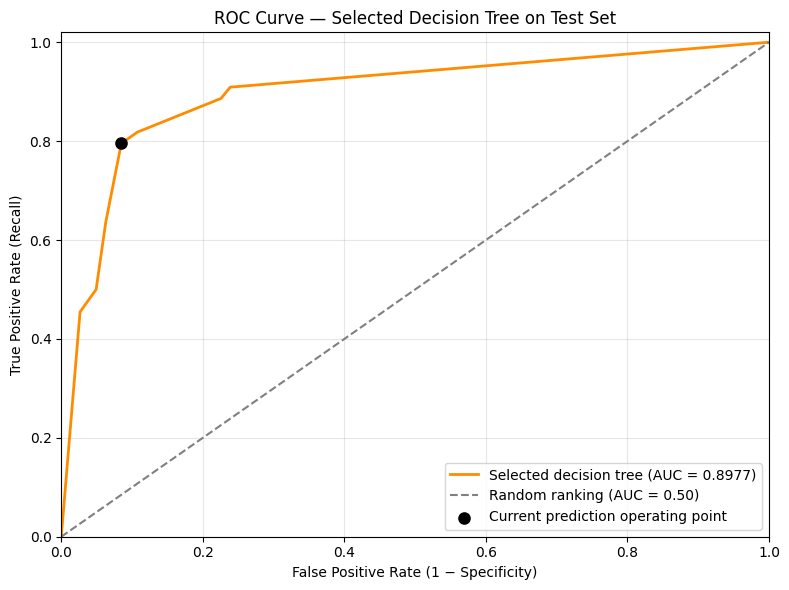

Test ROC AUC: 0.8977


In [ ]:
# --------------------------------------------------
# 1. Define the cost matrix
# Rows = actual labels; columns = predicted labels
# Label order: [0 = not bankrupt, 1 = bankrupt]
# --------------------------------------------------
COST_FP = 1.0
COST_FN = 20.0

cost_matrix = np.array([
    [0.0,     COST_FP],
    [COST_FN, 0.0]
])


def mean_classification_cost(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    total_cost = np.sum(cm * cost_matrix)
    return total_cost / len(y_true)


cost_scorer = make_scorer(
    mean_classification_cost,
    greater_is_better=False
)

# --------------------------------------------------
# 2. Define CV and check feasible sampling ratios
# --------------------------------------------------
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store the splits so feasibility checks and search use
# exactly the same folds.
cv_splits = list(cv.split(X_train, y_train))

minimum_feasible_ratio = max(
    y_train.iloc[train_idx].value_counts().min()
    / y_train.iloc[train_idx].value_counts().max()
    for train_idx, _ in cv_splits
)

candidate_ratios = [
    1.0,       # 1:1 majority:minority
    1 / 2,     # 2:1
    1 / 3,     # 3:1
    1 / 5,     # 5:1
    0.1        # 10:1
]

valid_ratios = [
    ratio for ratio in candidate_ratios
    if ratio >= minimum_feasible_ratio
]

print("\nFeasible sampling_strategy values:")
print(valid_ratios)

# --------------------------------------------------
# 3. Pipeline and parameter grid
# --------------------------------------------------
pipeline = ImbPipeline([
    ("sampler", RandomUnderSampler(random_state=42)),
    ("model", DecisionTreeClassifier(random_state=42))
])

param_grid = [
    {
        # All original training observations
        "sampler": ["passthrough"],
        "model__max_depth": [3, 5, 8, None],
        "model__min_samples_leaf": [5, 10, 20],
        "model__class_weight": [
            None,
            "balanced",
            {0: 1, 1: 5},
            {0: 1, 1: 20}
        ]
    }
]

if valid_ratios:
    param_grid.append({
        "sampler": [RandomUnderSampler(random_state=42)],
        "sampler__sampling_strategy": valid_ratios,
        "model__max_depth": [3, 5, 8, None],
        "model__min_samples_leaf": [5, 10, 20],
        "model__class_weight": [None]
    })

# --------------------------------------------------
# 4. Select the model by minimum CV mean cost
# --------------------------------------------------
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={
        "neg_cost": cost_scorer,
        "ap": "average_precision",
        "precision": make_scorer(
            precision_score, zero_division=0
        ),
        "recall": make_scorer(
            recall_score, zero_division=0
        ),
        "f1": make_scorer(
            f1_score, zero_division=0
        )
    },
    refit="neg_cost",
    cv=cv_splits,
    n_jobs=-1,
    error_score="raise"
)

search.fit(X_train, y_train)

print("\nBest parameters:")
print(search.best_params_)

print("\nBest CV mean cost per firm:")
print(round(-search.best_score_, 4))

# CV metrics for the model selected by cost
best_idx = search.best_index_

print("\nCV metrics for the selected model:")
for metric in ["precision", "recall", "f1", "ap"]:
    value = search.cv_results_[f"mean_test_{metric}"][best_idx]
    print(f"{metric}: {value:.4f}")

# --------------------------------------------------
# 5. Evaluate selected model on unchanged test set
# --------------------------------------------------
best_model = search.best_estimator_

y_pred = best_model.predict(X_test)

bankrupt_column = list(best_model.classes_).index(1)
p_bankrupt = best_model.predict_proba(X_test)[:, bankrupt_column]

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

test_total_cost = float(np.sum(cm * cost_matrix))
test_mean_cost = test_total_cost / len(y_test)

print("\nTest confusion matrix — label order [0, 1]:")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

print("\nTest classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not bankrupt", "Bankrupt"],
    zero_division=0
))

print("Test average precision:",
      round(average_precision_score(y_test, p_bankrupt), 4))

print("\nCost breakdown:")
print(f"False-positive cost: {fp} × {COST_FP} = {fp * COST_FP:.2f}")
print(f"False-negative cost: {fn} × {COST_FN} = {fn * COST_FN:.2f}")
print(f"Total test cost: {test_total_cost:.2f}")
print(f"Mean test cost per firm: {test_mean_cost:.4f}")

# --------------------------------------------------
# 6. Compare against trivial decision rules
# --------------------------------------------------
always_healthy = np.zeros(len(y_test), dtype=int)
always_bankrupt = np.ones(len(y_test), dtype=int)

print("\nBaseline total test costs:")
for name, predictions in [
    ("Always predict not bankrupt", always_healthy),
    ("Always predict bankrupt", always_bankrupt)
]:
    baseline_cost = (
        mean_classification_cost(y_test, predictions)
        * len(y_test)
    )
    print(f"{name}: {baseline_cost:.2f}")
# --------------------------------------------------
# 7. Plot test ROC curve and calculate ROC AUC
# --------------------------------------------------
# Use bankruptcy probabilities, not hard class predictions
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    p_bankrupt,
    pos_label=1
)

test_roc_auc = roc_auc_score(y_test, p_bankrupt)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"Selected decision tree (AUC = {test_roc_auc:.4f})"
)

# Random-ranking reference line
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Random ranking (AUC = 0.50)"
)

# Mark the operating point from the model's current predictions
current_fpr = fp / (fp + tn)
current_tpr = tp / (tp + fn)

plt.scatter(
    current_fpr,
    current_tpr,
    color="black",
    s=65,
    zorder=5,
    label="Current prediction operating point"
)

plt.xlabel("False Positive Rate (1 − Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Selected Decision Tree on Test Set")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Test ROC AUC: {test_roc_auc:.4f}")

AdaBoost with Random Undersampling

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

# 1. Define the base learner (Decision Stump)
base_stump = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# 2. AdaBoost + Random Undersampling pipeline
adaboost_under = ImbPipeline([
    ("sampler", RandomUnderSampler(
        sampling_strategy=1/3,
        random_state=42
    )),
    ("model", AdaBoostClassifier(
        estimator=base_stump,
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])

# 3. Evaluate using 5-Fold Stratified Cross-Validation
ada_scores = cross_validate(
    adaboost_under,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 4. Store evaluation results
ada_results = [{
    "Model": "AdaBoost - Undersampling",
    "Accuracy": ada_scores["test_Accuracy"].mean(),
    "Precision": ada_scores["test_Precision"].mean(),
    "Recall": ada_scores["test_Recall"].mean(),
    "F1-score": ada_scores["test_F1-score"].mean(),
    "Average Precision": ada_scores[
        "test_Average Precision"
    ].mean(),
    "AP Std": ada_scores[
        "test_Average Precision"
    ].std()
}]

# Convert into DataFrame
ada_results_df = pd.DataFrame(ada_results)

display(ada_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,AdaBoost - Undersampling,0.9254,0.2665,0.739,0.3906,0.4025,0.0666


Gradient Boosting with Random Undersampling

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# 1. Gradient Boosting + Random Undersampling pipeline
gb_under = ImbPipeline([
    ("sampler", RandomUnderSampler(
        sampling_strategy=1/3,
        random_state=42
    )),
    ("model", GradientBoostingClassifier(
        loss="log_loss",
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

# 2. Evaluate using 5-Fold Stratified Cross-Validation
gb_scores = cross_validate(
    gb_under,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 3. Store evaluation results
gb_results = [{
    "Model": "Gradient Boosting - Undersampling",
    "Accuracy": gb_scores["test_Accuracy"].mean(),
    "Precision": gb_scores["test_Precision"].mean(),
    "Recall": gb_scores["test_Recall"].mean(),
    "F1-score": gb_scores["test_F1-score"].mean(),
    "Average Precision": gb_scores[
        "test_Average Precision"
    ].mean(),
    "AP Std": gb_scores[
        "test_Average Precision"
    ].std()
}]

gb_results_df = pd.DataFrame(gb_results)

display(gb_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Average Precision,AP Std
0,Gradient Boosting - Undersampling,0.9283,0.2752,0.7162,0.3953,0.3912,0.0714


# 5. Precision-Recall Curve

# 6. Threshold Selection

# Export Models

In [ ]:
# Export train models
# Run the setup, data-loading, preprocessing and model-development cells first
import joblib
import re
from pathlib import Path
from importlib.metadata import version
from sklearn.base import clone
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

EXPORT_DIR = Path("exported_models")
# Optional thresholds previously selected on TRAINING/validation predictions
# Unlisted models retain their own default predict() rule
EXPORT_THRESHOLDS = {}

# Include every reported model, regardless of performance
# Each grid search contributes its tuned estimator, not every grid/fold trial
models_to_export = {
    **baseline_models,
    "Tuned Logistic Regression": logistic_grid.best_estimator_,
    "Tuned Decision Tree": dt_search.best_estimator_,
    **imbalance_models,
    "Cost-Sensitive Decision Tree": search.best_estimator_,
    "AdaBoost - Undersampling": adaboost_under,
    "Gradient Boosting - Undersampling": gb_under
}

unknown_thresholds = set(EXPORT_THRESHOLDS) - set(models_to_export)
if unknown_thresholds:
    raise ValueError(f"Thresholds supplied for unknown models: {unknown_thresholds}")
for export_name, export_threshold in EXPORT_THRESHOLDS.items():
    if export_threshold is not None and (
        isinstance(export_threshold, (bool, str))
        or not np.isscalar(export_threshold)
        or not np.isfinite(export_threshold)
        or not 0 <= export_threshold <= 1
    ):
        raise ValueError(f"Invalid threshold for {export_name}: expected None or 0 to 1.")

# Use the original training split; do not fit on testing
export_features = X_train.columns.tolist()
export_versions = {
    package: version(package)
    for package in [
        "scikit-learn", "imbalanced-learn",
        "numpy", "pandas", "scipy", "joblib"
    ]
}
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
export_records = []

for export_number, (export_name, export_estimator) in enumerate(
    models_to_export.items(), start=1
):
    # GridSearchCV(refit=...) already fitted its selected estimator
    # cross_validate() fitted temporary copies, leaving its input unfitted
    try:
        check_is_fitted(export_estimator)
        export_model = export_estimator
        export_fit_action = "Preserved existing fitted model"
    except NotFittedError:
        export_model = clone(export_estimator)
        export_model.fit(X_train, y_train)
        export_fit_action = "Fitted a copy on the training split"

    if hasattr(export_model, "feature_names_in_"):
        if list(export_model.feature_names_in_) != export_features:
            raise ValueError(f"Training feature names/order differ for {export_name}.")
    if hasattr(export_model, "n_features_in_"):
        if export_model.n_features_in_ != len(export_features):
            raise ValueError(f"Training feature count differs for {export_name}.")
    if set(export_model.classes_) != {0, 1}:
        raise ValueError(f"Expected binary labels 0 and 1 for {export_name}.")

    export_threshold = EXPORT_THRESHOLDS.get(export_name)
    export_bundle = {
        "model": export_model,
        "model_name": export_name,
        "model_parameters": export_model.get_params(deep=True),
        "feature_names": export_features,
        "positive_class": 1,
        "threshold": None if export_threshold is None else float(export_threshold),
        "cost_matrix": cost_matrix.copy(),
        "package_versions": export_versions
    }

    # Numbered (prepended) file name to distinguish between models of similar type
    export_slug = re.sub(r"[^a-z0-9]+", "_", export_name.lower()).strip("_")
    export_path = EXPORT_DIR / f"{export_number:02d}_{export_slug}.joblib"
    # Note that rerunning this cell will replace existing model bundles
    joblib.dump(export_bundle, export_path)

    # Check if export was successful
    export_loaded = joblib.load(export_path)
    export_check_rows = X_train.iloc[:10]
    np.testing.assert_allclose(
        export_model.predict_proba(export_check_rows),
        export_loaded["model"].predict_proba(export_check_rows)
    )
    np.testing.assert_array_equal(
        export_model.predict(export_check_rows),
        export_loaded["model"].predict(export_check_rows)
    )
    export_records.append({
        "Model": export_name,
        "File": str(export_path),
        "Threshold": "model default" if export_threshold is None else export_threshold,
        "Fit action": export_fit_action,
        "Features": len(export_features)
    })

export_summary_df = pd.DataFrame(export_records)
export_summary_df.to_csv(EXPORT_DIR / "model_index.csv", index=False)
display(export_summary_df)
print(f"Exported all {len(export_summary_df)} model configurations to {EXPORT_DIR.resolve()}")
print("All save/load prediction checks passed.")
print("In the notebook for predictions, set MODEL_PATH to any File listed above.")
